**Finding Candidate SAE Features Associated with Harmful Requests**

**Research idea**

My broader research asks how persona framing changes a language model's internal representations and its answers. The earlier coverage pilot showed why an observed feature inventory should not be treated as a complete safety map.

Here I ask a narrower question: **can we select a small group of SAE features whose activity distinguishes harmful from benign requests, even without a complete inventory??**

This is a separate dataset and study. Good classification in this experiment would not mean the earlier inventory became saturated.


In [ ]:
%pip -q install "transformers==4.51.3" "accelerate>=1.2,<2" "huggingface_hub==0.36.2" safetensors numpy pandas scipy matplotlib

In [ ]:
"""CPU-only inventory statistics. No behavioral safety conclusions."""
import hashlib, json, re
import numpy as np

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

def normalize(text):
    return re.sub(r'\s+', ' ', str(text)).strip().casefold()

def partition(rows, discovery_n, test_n, seed=42, return_stats=False):
    """Exact normalized duplicates removed; conflicting labels excluded.
    With topics, hold out whole topics. Without topics, random unseen requests.
    """
    unique = {}
    counts = {}
    ambiguous = set()
    for row in rows:
        assert row['label'] in ('harmful', 'harmless')
        text = str(row['prompt']).strip()
        if not text: continue
        key = normalize(text)
        counts[key] = counts.get(key, 0) + 1
        if key in unique:
            if unique[key]['label'] != row['label']:
                ambiguous.add(key)
            if row.get('topic') and unique[key].get('topic') != row['topic']:
                raise ValueError('Same prompt assigned different topics')
            continue
        unique[key] = dict(row, prompt=text, prompt_hash=digest(key))
    stats = {'duplicate_rows': sum(n-1 for key,n in counts.items() if key not in ambiguous),
             'ambiguous_prompts': len(ambiguous),
             'ambiguous_rows': sum(counts[key] for key in ambiguous)}
    rows = sorted((row for key,row in unique.items() if key not in ambiguous),
                  key=lambda r: r['prompt_hash'])
    rng = np.random.default_rng(seed)
    topic_mode = all(bool(r.get('topic')) for r in rows)
    if any(bool(r.get('topic')) for r in rows) and not topic_mode:
        raise ValueError('Provide topic for every row or none')
    if topic_mode:
        topics = sorted({r['topic'] for r in rows})
        assert len(topics) >= 5, 'Topic split requires at least five topics'
        rng.shuffle(topics)
        reserved = set(topics[:max(1, int(np.ceil(len(topics)*.2)))])
    out = {'discovery': [], 'test': []}
    for label in ('harmful', 'harmless'):
        candidates = [r for r in rows if r['label'] == label]
        if topic_mode:
            a = [r for r in candidates if r['topic'] not in reserved]
            b = [r for r in candidates if r['topic'] in reserved]
            rng.shuffle(a); rng.shuffle(b)
        else:
            rng.shuffle(candidates)
            b, a = candidates[:test_n], candidates[test_n:]
        assert len(a) >= discovery_n and len(b) >= test_n, f'Insufficient unique {label} rows after split'
        out['discovery'] += a[:discovery_n]
        out['test'] += b[:test_n]
    for phase in out:
        # Interleave labels so partial runs collect both groups evenly.
        a = [r for r in out[phase] if r['label']=='harmful']
        b = [r for r in out[phase] if r['label']=='harmless']
        out[phase] = [r for pair in zip(a,b) for r in pair]
    assert not ({r['prompt_hash'] for r in out['discovery']} & {r['prompt_hash'] for r in out['test']})
    result = (out, 'held-out topics' if topic_mode else 'unseen requests; topics NOT held out')
    return (*result, stats) if return_stats else result

def empty_inventory(width):
    return {'count': np.zeros(width, dtype=np.int64), 'sum': np.zeros(width), 'n': 0}

def update_inventory(inv, ids, values):
    ids=np.asarray(ids,dtype=int); values=np.asarray(values,dtype=float)
    assert len(ids)==len(set(ids.tolist())) and len(ids)==len(values)
    assert np.all(values>0) and np.isfinite(values).all()
    assert np.all((ids>=0)&(ids<len(inv['count'])))
    unseen=inv['count'][ids]==0
    mass=float(values[unseen].sum()/values.sum()) if values.sum()>0 else None
    new=int(unseen.sum())
    inv['count'][ids]+=1; inv['sum'][ids]+=values; inv['n']+=1
    return new,mass

def outside(ids, values, frozen_ids):
    values=np.asarray(values,dtype=float)
    mask=np.array([int(j) not in frozen_ids for j in ids],dtype=bool)
    return {'novel': bool(mask.any()), 'new_count': int(mask.sum()),
            'outside_mass': float(values[mask].sum()/values.sum()) if values.sum()>0 else None}

def upper_bound(k,n,alpha=.05):
    from scipy.stats import beta
    assert 0<=k<=n and n>0
    return 1. if k==n else float(beta.ppf(1-alpha,k+1,n-k))

def jaccard(a,b):
    a,b=set(a),set(b)
    return len(a&b)/len(a|b) if a|b else 1.

def candidate_statistics(observations, layer, width, top_k=20):
    """Discovery only. Equal topic weighting where topics exist; no test tuning."""
    rows=[o for o in observations if o['phase']=='discovery']
    topics=sorted({o.get('topic','') for o in rows})
    differences=[]; strengths=[]; harmful_counts=np.zeros(width,dtype=int)
    harmless_counts=np.zeros(width,dtype=int)
    for topic in topics:
        groups=[]
        for label in ('harmful','harmless'):
            selected=[o for o in rows if o.get('topic','')==topic and o['label']==label]
            if not selected:
                raise ValueError('Every discovery topic needs both harmful and harmless examples')
            inv=empty_inventory(width)
            for o in selected:
                c=o['layers'][str(layer)];update_inventory(inv,c['ids'],c['values'])
            groups.append(inv)
        h,b=groups
        harmful_counts+=h['count'];harmless_counts+=b['count']
        differences.append(h['count']/h['n']-b['count']/b['n'])
        strengths.append(h['sum']/h['n']-b['sum']/b['n'])
    delta=np.mean(differences,axis=0); strength=np.mean(strengths,axis=0)
    eligible=np.flatnonzero((delta>0)&(harmful_counts>=3))
    ranked=sorted(eligible.tolist(),key=lambda j:(-delta[j],j))[:top_k]
    return {'selected_ids':ranked,'frequency_difference':delta.tolist(),
            'mean_activation_difference':strength.tolist(),
            'positive_topic_fraction':(np.asarray(differences)>0).mean(axis=0).tolist(),
            'harmful_count':harmful_counts.tolist(),'harmless_count':harmless_counts.tolist(),
            'set_difference_ids':np.flatnonzero((harmful_counts>0)&(harmless_counts==0)).tolist(),
            'topic_adjusted':topics!=[''],'topics':topics}

def candidate_score(capture, selected):
    """Fraction of frozen candidate IDs firing; bounded and no fitted test threshold."""
    return len(set(capture['ids'])&set(selected))/len(selected) if selected else None

CODE_SHA='4e776d12e1dc41f1a97402feb19c93bc859ca87ecd06cd2723df41756a7564da'
PROTOCOL="# Direct-request SAE inventory pilot, version 2\n\n## Candidate D extension (version 3)\nRetains the inventory endpoints below. Discovery-only candidate ranking selects at most 20 positive firing-frequency differences with at least three harmful activations; ties use feature ID. Mean activation differences are descriptive and do not select candidates. With complete topic labels, both differences are equally averaged within topics; any discovery topic missing one label fails explicitly. Default WildJailbreak ranking is unadjusted for topic and cannot isolate topic effects. Literal harmful-minus-harmless feature IDs are also saved in frozen.json for comparison, not assumed safety-specific.\nFrozen candidate score is the fraction of selected features active on an evaluation request. AUROC compares harmful versus harmless request labels, with no threshold or weights learned on test data. No candidate means no score, not zero performance. Results in smoke mode are technical checks. These are association measurements, not observed refusal or causal validation. Existing v2 ZIPs cannot resume into changed code; keep the original notebook for unfinished v2 runs.\n\n## Question and scope\nCan fixed SAE feature inventories cover activations elicited by fresh direct harmful and harmless requests? This is an activation inventory study, not a refusal classifier or causal safety test. No responses are generated; dataset intent labels are not observed model behavior. No persona interventions or wrappers are introduced.\n\n## Setup\nKaggle: fresh notebook/session, Internet, T4 GPU. Enable the HF_TOKEN secret already approved for Gemma. Also personally accept the WildJailbreak dataset's access terms at https://huggingface.co/datasets/allenai/wildjailbreak using the same Hugging Face account. Token must allow reading public gated repositories. Do not paste the token into cells or chat.\nDataset file downloads automatically on Kaggle (~531 MB). Model and three 16k SAE weight files also download there. No local GPU or local model storage is required. Model/SAE revisions are pinned; dataset revision is resolved and recorded. Publisher metadata verifies the model and hook, but does not certify training-model commit lineage.\n\n## Data\nOnly official WildJailbreak `vanilla_harmful` and `vanilla_benign` rows; no adversarial rows or completions. Benign requests often concern sensitive topics, not a representative sample of all ordinary language. Source: https://huggingface.co/datasets/allenai/wildjailbreak ; ODC-BY attribution: Jiang et al., WildTeaming / WildJailbreak, https://arxiv.org/abs/2406.18510 . Dataset labels may contain noise and should be audited before paper claims.\nExact normalized duplicates are removed before splitting. If a prompt appears with both labels, every occurrence is excluded from both groups; duplicate and ambiguous exclusion counts are recorded in the configuration. Near duplicates and common templates may remain. Token counts above 512 are explicitly excluded, counted, and never silently truncated. Claims exclude these longer inputs.\nDefault split is random unseen requests from the source distribution, NOT held-out topics. Optional CSV columns `prompt,label,topic` enable a deterministic 20% whole-topic holdout; each topic needs balanced enough labels for requested counts. Label is exactly `harmful` or `harmless`. All rows need a topic or none. Human grouping of related paraphrases and topics is needed for stronger generalization claims.\nModes: smoke 50 discovery +30 evaluation per label (160 requests total); pilot 1000 +500 (3000 total); full 10000 +1000 (22000 total). No oversampling to manufacture requested size. Different modes are separate runs; different seeds do not guarantee disjoint datasets across modes. If any evaluation data inform changes, reserve a genuinely new final confirmation set before claiming confirmation.\n\n## Measurements\nThree matched residual-stream SAEs nearest 25%, 50%, and 85% model depth selected from pinned repository metadata before seeing data. Actual layers/folders/configurations logged. Same SAE used for both labels at a layer. One final formatted-prompt token per input. This does not trace the whole sequence or establish special functions of early/middle/late layers.\nJumpReLU encode using documented no-input-bias-subtraction convention. Strictly positive latent activations form support. Reconstruction error logged per request/layer; errors are not silently discarded. FP32 with deterministic settings and repeated-capture/resume checks.\nSix separate cumulative unions. Per-request discovery curves measure newly observed IDs and outside activation BEFORE union update. Frozen unions never expand on evaluation. Saved sparse activations permit later co-activation/strength analysis; the notebook does not yet infer manifolds from them.\nOutside mass is sum of nonnegative SAE activation values outside the inventory divided by their total. It is a within-dictionary descriptive metric; decoder scales and different dictionaries limit cross-layer numerical comparisons. Zero-activation inputs are separately reported, not silently counted as perfect mass coverage.\n\n## Prespecified endpoints\nAt maximum discovery budget, freeze regardless of whether new IDs are still appearing. No automatic early stopping or repeated evaluation-set inspection. Report per-group novelty rate, mean and 95th percentile outside mass, dictionary fraction, harmful/harmless Jaccard overlap, and reconstruction error. Near-total dictionary coverage is not safety-specific.\nProvisional novelty target <1%, supported only if one-sided Clopper-Pearson bound with Bonferroni alpha .05/6 is below .01 after completion and outside smoke mode. Assumption: sampled requests are approximately independent from the declared source distribution; template clustering weakens this inference. Outside mean <1% is an observed descriptive target only, without a population confidence claim. Small smoke tests cannot support these targets. An average does not override failure on individual topics.\nNo automatic pass label for overall safety geometry. Stable ID inventory does not imply stable strengths/combinations, completeness of the SAE, or a causal refusal mechanism. Follow-up behavior and reconstruction fidelity tests would be separate work.\n\n## Resume and outputs\nEvery completed request appended to observations.jsonl. Soft time limit checked between requests; checkpoint ZIP exported every 500 requests and on exit from capture. Upload ZIP as a Kaggle input, set RESUME_ZIP to its actual path, keep MODE and all scientific settings unchanged. Runtime budget can increase. Resume validates code/data/settings/dependency fingerprints and numerical capture. A fresh session avoids conflicting archives or duplicate resident models.\nSaved: config.json, request manifests, sparse observations, frozen.json, inventory CSV per layer, discovery_curves.csv, discovery.png, heldout_per_request.csv, topic_results.csv when applicable, summary.json, this protocol. Incomplete runs are marked incomplete and do not support the endpoint.\n\n## Resource estimate\nMeasure seconds/request after the first 50 captures; notebook estimates remaining time. There is no promised fixed runtime or saturation at 10000. Full mode may need multiple Kaggle sessions. Start smoke. Requires no generated harmful answers or external judge calls.\n"

**Settings — first run smoke; pilot and full use new independent run IDs**

In [ ]:
MODE='smoke'                 # smoke: 50/group; pilot: 1000/group; full: 10000/group discovery
RESUME_ZIP=None              # Kaggle input path to this notebook's result ZIP
CSV_PATH=None                # optional CSV: prompt,label (harmful/harmless), optional topic
MINUTES=45                  # soft session budget, exports checkpoint; resume unchanged settings
SEED=20261009
TOP_K=20                    # fixed discovery ranking; never tune on held-out results
MODEL_ID='google/gemma-3-1b-it'
MODEL_REVISION='dcc83ea841ab6100d6b47a070329e1ba4cf78752'
SAE_REPO='google/gemma-scope-2-1b-it'
SAE_REVISION='b0fa29457c3601df0a70c48a15534c738d7c10e0'
DATASET_ID='allenai/wildjailbreak'
DATASET_REVISION=None       # resolved once, saved; resume uses original revision
MAX_TOKENS=512              # long requests explicitly excluded BEFORE splitting; no truncation
BATCH_PER_GROUP=100
assert MODE in ('smoke','pilot','full')
DISCOVERY_N,TEST_N={'smoke':(50,30),'pilot':(1000,500),'full':(10000,1000)}[MODE]
NOVEL_RATE_TARGET=.01
OUTSIDE_MEAN_TARGET=.01
# No persona prompts, response generation, or causal edits in this notebook.



**Setup and model/dictionary metadata**

In [ ]:
import os,time,zipfile,shutil,gc,importlib.metadata
from pathlib import Path
import pandas as pd
BASE=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
os.environ['HF_HOME']=str(BASE/'hf_inventory_v2_cache')
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
import torch
from transformers import AutoTokenizer,AutoModelForCausalLM,AutoConfig,set_seed
from huggingface_hub import hf_hub_download,HfApi
from safetensors.torch import load_file
from IPython.display import display,FileLink
assert torch.cuda.is_available(),'Enable GPU and Internet in Kaggle.'
try:
 from kaggle_secrets import UserSecretsClient
 TOKEN=UserSecretsClient().get_secret('HF_TOKEN')
except Exception:TOKEN=os.environ.get('HF_TOKEN')
assert TOKEN,'Enable HF_TOKEN secret. Accept Gemma and WildJailbreak access terms on Hugging Face.'
api=HfApi(token=TOKEN)
resume_config=None
if RESUME_ZIP:
 with zipfile.ZipFile(RESUME_ZIP) as archive:
  assert archive.testzip() is None
  resume_config=json.loads(archive.read('config.json'))
  assert resume_config['code']==CODE_SHA, 'Resume must use identical notebook code'
mc=AutoConfig.from_pretrained(MODEL_ID,revision=MODEL_REVISION,token=TOKEN)
L=int(mc.num_hidden_layers)
files=api.list_repo_files(SAE_REPO,revision=SAE_REVISION)
available={}
for name in files:
 match=re.fullmatch(r'resid_post/layer_(\d+)_width_16k_l0_medium/config.json',name)
 if match:available[int(match.group(1))]=name.rsplit('/',1)[0]
assert len(available)>=3,'Need three matched 16k medium residual SAEs; no silent substitute'
# Chosen by depth, before looking at any activations/outcomes.
layers=[]
for fraction in (.25,.5,.85):
 target=round((L-1)*fraction)
 chosen=min((v for v in available if v not in layers),key=lambda v:(abs(v-target),v))
 layers.append(chosen)
assert layers==sorted(layers)
sae_cfg={}
for layer in layers:
 p=hf_hub_download(SAE_REPO,available[layer]+'/config.json',revision=SAE_REVISION,token=TOKEN)
 c=json.loads(Path(p).read_text())
 assert c['model_name']==MODEL_ID and c['hf_hook_point_in']==f'model.layers.{layer}.output'
 assert c['hf_hook_point_out']==c['hf_hook_point_in'] and c['architecture']=='jump_relu' and not c['affine_connection']
 sae_cfg[layer]=c
print('Measured early/middle/late layers:',layers,'of',L)
print('GPU:',torch.cuda.get_device_name(0),'Free disk GB:',round(shutil.disk_usage(BASE).free/2**30,1))
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION,token=TOKEN)



**Direct-request dataset, deduplication, and split fixed before discovery**

In [ ]:
if CSV_PATH:
 source_bytes=Path(CSV_PATH).read_bytes()
 df=pd.read_csv(CSV_PATH).fillna('')
 assert {'prompt','label'}<=set(df.columns)
 rows=df[['prompt','label']+(['topic'] if 'topic' in df else [])].to_dict('records')
 source={'csv_sha256':hashlib.sha256(source_bytes).hexdigest()}
else:
 revision=(resume_config['source']['revision'] if resume_config else DATASET_REVISION) or api.dataset_info(DATASET_ID).sha
 # Official gated file (~531MB). Requires user acceptance of AI2 terms; no bypass.
 data_path=hf_hub_download(DATASET_ID,'train/train.tsv',repo_type='dataset',revision=revision,token=TOKEN)
 rows=[]
 for chunk in pd.read_csv(data_path,sep='\t',usecols=['vanilla','data_type'],chunksize=10000):
  selected=chunk[chunk.data_type.isin(['vanilla_harmful','vanilla_benign'])]
  for prompt,kind in selected[['vanilla','data_type']].itertuples(index=False,name=None):
   if isinstance(prompt,str):rows.append({'prompt':prompt,'label':'harmful' if kind=='vanilla_harmful' else 'harmless'})
 source={'dataset':DATASET_ID,'revision':revision,'file':'train/train.tsv','license':'odc-by'}
# Filter before splitting; publish exclusion counts. Never silently shorten a request.
filtered=[];excluded={'harmful':0,'harmless':0}
for row in rows:
 assert row['label'] in excluded
 ids=tokenizer.apply_chat_template([{'role':'user','content':str(row['prompt'])}],tokenize=True,add_generation_prompt=True)
 if len(ids)>MAX_TOKENS:excluded[row['label']]+=1
 else:filtered.append(dict(row,tokens=len(ids)))
# Modes use different seeds: upgrading is a separate study, not confirmation of inspected smoke data.
mode_seed=SEED+{'smoke':0,'pilot':1000,'full':2000}[MODE]
streams,split_scope,dedup_stats=partition(filtered,DISCOVERY_N,TEST_N,mode_seed,return_stats=True)
config={'code':CODE_SHA,'mode':MODE,'seed':mode_seed,'model':MODEL_ID,'model_revision':MODEL_REVISION,
 'sae':SAE_REPO,'sae_revision':SAE_REVISION,'layers':layers,'folders':{str(k):available[k] for k in layers},
 'sae_configs':{str(k):v for k,v in sae_cfg.items()},'source':source,'stream_hash':digest(streams),'split_scope':split_scope,
 'discovery_per_group':DISCOVERY_N,'test_per_group':TEST_N,'batch':BATCH_PER_GROUP,'max_tokens':MAX_TOKENS,
 'excluded_long':excluded,'deduplication':dedup_stats,
 'dtype':'float32','threshold':'checkpoint JumpReLU strictly positive',
 'targets':{'novel_rate':NOVEL_RATE_TARGET,'mean_outside_mass':OUTSIDE_MEAN_TARGET},'candidate_top_k':TOP_K,
 'versions':{k:importlib.metadata.version(k) for k in ('torch','transformers','numpy','scipy','huggingface_hub','safetensors')}}
if resume_config:assert config==resume_config,'Settings/data/dependencies differ; do not combine runs'
OUT=BASE/'sae_candidates_v3'/digest(config)[:12];OUT.mkdir(parents=True,exist_ok=True)
if RESUME_ZIP:
 with zipfile.ZipFile(RESUME_ZIP) as archive:
  # Whitelist output paths, never extract arbitrary archive paths.
  for name in archive.namelist():
   if name in ('observations.jsonl','frozen.json'):
    p=OUT/name;data=archive.read(name)
    if p.exists():assert p.read_bytes()==data,'Conflicting output: start a fresh Kaggle session'
    else:p.write_bytes(data)
(OUT/'config.json').write_text(json.dumps(config,indent=2))
(OUT/'PROTOCOL.md').write_text(PROTOCOL)
# Save request manifests for auditing; observations carry IDs, labels and sparse coordinates.
for phase in streams:pd.DataFrame(streams[phase]).to_csv(OUT/(phase+'_manifest.csv'),index=False)
observations=[]
log_path=OUT/'observations.jsonl'
if log_path.exists():
 lines=log_path.read_text().splitlines()
 for i,line in enumerate(lines):
  try:observations.append(json.loads(line))
  except json.JSONDecodeError:
   assert i==len(lines)-1,'Corrupt checkpoint'
   log_path.write_text('\n'.join(lines[:i])+'\n')
plan=[(phase,i,row) for phase in ('discovery','test') for i,row in enumerate(streams[phase])]
for obs,(phase,i,row) in zip(observations,plan):
 assert obs['phase']==phase and obs['index']==i and obs['prompt_hash']==row['prompt_hash']
assert len(observations)<=len(plan)
assert not any(o['phase']=='test' for o in observations) or (OUT/'frozen.json').exists()
print('Scope:',split_scope,'Requests:',len(plan),'Already captured:',len(observations),'Excluded long:',excluded,'Deduplication:',dedup_stats)
print('Output:',OUT)

def export():
 archive=shutil.make_archive(str(BASE/('sae_candidates_v3_'+OUT.name)),'zip',OUT)
 print('Checkpoint ZIP:',archive);display(FileLink(archive))



**Load matched weights and capture all three layers in each forward pass**

In [ ]:
set_seed(42);torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False;torch.use_deterministic_algorithms(True)
for old in ('model','weights'):globals().pop(old,None)
gc.collect();torch.cuda.empty_cache()
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=MODEL_REVISION,token=TOKEN,
 torch_dtype=torch.float32,device_map={'':'cuda:0'},attn_implementation='eager').eval()
weights={}
for layer in layers:
 path=hf_hub_download(SAE_REPO,available[layer]+'/params.safetensors',revision=SAE_REVISION,token=TOKEN)
 w={k:v.float().cuda() for k,v in load_file(path).items()}
 assert w['w_enc'].shape==(mc.hidden_size,sae_cfg[layer]['width'])
 assert w['w_dec'].shape==(sae_cfg[layer]['width'],mc.hidden_size)
 assert all(torch.isfinite(v).all() for v in w.values()) and (w['threshold']>=0).all()
 weights[layer]=w

@torch.inference_mode()
def observe(row):
 ids=tokenizer.apply_chat_template([{'role':'user','content':row['prompt']}],tokenize=True,add_generation_prompt=True,return_tensors='pt').to('cuda:0')
 assert ids.shape[1]<=MAX_TOKENS
 captured={};handles=[]
 def make_hook(layer):
  def hook(module,args,out):
   h=(out[0] if isinstance(out,tuple) else out)[0,-1].float()
   w=weights[layer];pre=h@w['w_enc']+w['b_enc']
   z=torch.relu(pre)*(pre>w['threshold']) # checkpoint convention: no input bias subtraction
   active=torch.nonzero(z>0).flatten()
   assert torch.isfinite(h).all() and torch.isfinite(z).all()
   captured[str(layer)]={'ids':active.cpu().tolist(),'values':z[active].cpu().tolist(),
    'relative_error':float((h-z@w['w_dec']-w['b_dec']).norm()/h.norm().clamp_min(1e-12))}
  return hook
 try:
  for layer in layers:handles.append(model.model.layers[layer].register_forward_hook(make_hook(layer)))
  model(input_ids=ids,attention_mask=torch.ones_like(ids),use_cache=False,logits_to_keep=1)
 finally:
  for handle in handles:handle.remove()
 assert len(captured)==3
 return captured



**Build separate groups; freeze before evaluation; checkpoint and resume**

In [ ]:

def inventories():
 inv={(str(l),label):empty_inventory(sae_cfg[l]['width']) for l in layers for label in ('harmful','harmless')}
 curves=[]
 for obs in observations:
  if obs['phase']!='discovery':continue
  for layer,capture in obs['layers'].items():
   v=inv[layer,obs['label']];new,mass=update_inventory(v,capture['ids'],capture['values'])
   curves.append({'layer':int(layer),'label':obs['label'],'n':v['n'],'new_ids':new,'outside_mass_before_update':mass,
    'union_size':int((v['count']>0).sum())})
 return inv,curves

def freeze():
 assert sum(o['phase']=='discovery' for o in observations)==2*DISCOVERY_N
 inv,_=inventories()
 frozen={'config_hash':digest(config),'discovery_hash':digest([o for o in observations if o['phase']=='discovery']),
 'groups':{layer+'_'+label:np.flatnonzero(v['count']).tolist() for (layer,label),v in inv.items()},
 'candidates':{str(l):candidate_statistics(observations,l,sae_cfg[l]['width'],TOP_K) for l in layers}}
 p=OUT/'frozen.json'
 if p.exists():assert json.loads(p.read_text())==frozen
 else:p.write_text(json.dumps(frozen,indent=2))
 return frozen

start=time.monotonic();added=0
try:
 ref=observe(streams['discovery'][0]);again=observe(streams['discovery'][0])
 for layer in ref:
  assert ref[layer]['ids']==again[layer]['ids']
  np.testing.assert_allclose(ref[layer]['values'],again[layer]['values'],rtol=1e-6,atol=1e-7)
  if observations:
   assert ref[layer]['ids']==observations[0]['layers'][layer]['ids'],'Resume numerical drift'
   np.testing.assert_allclose(ref[layer]['values'],observations[0]['layers'][layer]['values'],rtol=1e-6,atol=1e-7)
 for phase,i,row in plan[len(observations):]:
  if time.monotonic()-start>MINUTES*60:
   print('Soft budget reached. Resume this ZIP with unchanged settings.');break
  if phase=='test' and i==0:freeze()
  capture=observe(row)
  obs={'phase':phase,'index':i,'prompt_hash':row['prompt_hash'],'label':row['label'],'topic':row.get('topic',''), 'layers':capture}
  with log_path.open('a') as f:f.write(json.dumps(obs)+'\n');f.flush()
  observations.append(obs);added+=1
  if added%50==0:
   seconds=(time.monotonic()-start)/added
   print(len(observations),'/',len(plan),'requests;',round(seconds,2),'sec/request; estimated remaining',round((len(plan)-len(observations))*seconds/60,1),'min')
  if added%500==0:export()
finally:
 export()



**Figures, inventory tables, and bounded held-out results**

In [ ]:
inv,curves=inventories();pd.DataFrame(curves).to_csv(OUT/'discovery_curves.csv',index=False)
for layer in layers:
 a=inv[str(layer),'harmful'];b=inv[str(layer),'harmless'];width=len(a['count'])
 pd.DataFrame({'feature_id':np.arange(width),'harmful_count':a['count'],'harmless_count':b['count'],
  'harmful_frequency':a['count']/max(a['n'],1),'harmless_frequency':b['count']/max(b['n'],1),
  'harmful_mean_activation':a['sum']/max(a['n'],1),'harmless_mean_activation':b['sum']/max(b['n'],1)}).to_csv(OUT/f'layer_{layer}_inventory.csv',index=False)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,3,figsize=(15,8))
for col,layer in enumerate(layers):
 for label in ('harmful','harmless'):
  c=[r for r in curves if r['layer']==layer and r['label']==label]
  if not c:continue
  axes[0,col].plot([r['n'] for r in c],[r['union_size'] for r in c],label=label)
  chunks=[c[i:i+BATCH_PER_GROUP] for i in range(0,len(c),BATCH_PER_GROUP)]
  axes[1,col].plot([b[-1]['n'] for b in chunks],[sum(r['new_ids'] for r in b) for b in chunks],label=label)
 axes[0,col].set(title=f'Layer {layer}',xlabel='Requests in this group',ylabel='Distinct observed features');axes[0,col].legend()
 axes[1,col].set(xlabel='Requests in this group',ylabel='New features per batch (last may be partial)')
fig.suptitle('Direct-request activation inventories — not a causal safety map');fig.tight_layout();fig.savefig(OUT/'discovery.png',dpi=160);display(fig);plt.close(fig)
complete=len(observations)==len(plan)
summary={'complete':complete,'scope':split_scope,'mode':MODE,'layers':layers,'groups':[],
 'interpretation':'Dictionary coverage at selected layers and final prompt token. No refusal labels, causal claims, or universal safety completeness.'}
if sum(o['phase']=='discovery' for o in observations)==2*DISCOVERY_N:
 frozen=freeze();tests=[o for o in observations if o['phase']=='test'];metrics=[]
 candidate_results=[]
 from scipy.stats import mannwhitneyu
 for layer in layers:
  stats=frozen['candidates'][str(layer)];selected=stats['selected_ids']
  pd.DataFrame({'feature_id':np.arange(sae_cfg[layer]['width']),
   **{k:stats[k] for k in ('frequency_difference','mean_activation_difference','positive_topic_fraction','harmful_count','harmless_count')},
   'selected':[j in selected for j in range(sae_cfg[layer]['width'])]}).to_csv(OUT/f'layer_{layer}_candidate_ranking.csv',index=False)
  scores=[]
  for o in tests:
   scores.append({'label':o['label'],'topic':o['topic'],'prompt_hash':o['prompt_hash'],
    'candidate_firing_fraction':candidate_score(o['layers'][str(layer)],selected)})
  pd.DataFrame(scores).to_csv(OUT/f'layer_{layer}_candidate_test_scores.csv',index=False)
  h=[s['candidate_firing_fraction'] for s in scores if s['label']=='harmful']
  b=[s['candidate_firing_fraction'] for s in scores if s['label']=='harmless']
  auc=float(mannwhitneyu(h,b).statistic/(len(h)*len(b))) if selected and h and b else None
  candidate_results.append({'layer':layer,'selected_ids':selected,'topic_adjusted':stats['topic_adjusted'],
   'literal_harmful_minus_harmless_count':len(stats['set_difference_ids']),
   'heldout_auroc':auc,'complete':complete,
   'meaning':'Harmful-input association only; no refusal or causal safety labels'})
 summary['candidate_results']=candidate_results
 for obs in tests:
  for layer,c in obs['layers'].items():
   known=set(frozen['groups'][layer+'_'+obs['label']])
   metrics.append(dict(layer=int(layer),label=obs['label'],topic=obs['topic'],prompt_hash=obs['prompt_hash'],
    relative_error=c['relative_error'],**outside(c['ids'],c['values'],known)))
 pd.DataFrame(metrics).to_csv(OUT/'heldout_per_request.csv',index=False)
 # Six groups; Bonferroni-adjusted upper bounds for simultaneous novelty-rate statements.
 for layer in layers:
  for label in ('harmful','harmless'):
   m=[r for r in metrics if r['layer']==layer and r['label']==label]
   if not m:continue
   k=sum(r['novel'] for r in m);n=len(m);mass=[r['outside_mass'] for r in m if r['outside_mass'] is not None]
   upper=upper_bound(k,n,alpha=.05/6)
   group={'layer':layer,'label':label,'n':n,'novel_requests':k,'novel_rate':k/n,
    'simultaneous_95pct_novel_rate_upper_bound':upper,'mean_outside_mass':float(np.mean(mass)) if mass else None,
    'p95_outside_mass':float(np.quantile(mass,.95)) if mass else None,'zero_activation_requests':n-len(mass),
    'mean_relative_reconstruction_error':float(np.mean([r['relative_error'] for r in m])),
    'inventory_size':len(frozen['groups'][str(layer)+'_'+label]),'dictionary_width':sae_cfg[layer]['width'],
    'novel_rate_target_supported':bool(complete and MODE!='smoke' and upper<NOVEL_RATE_TARGET),
    'mean_mass_target_observed':bool(complete and mass and np.mean(mass)<OUTSIDE_MEAN_TARGET)}
   group['dictionary_fraction']=group['inventory_size']/group['dictionary_width']
   summary['groups'].append(group)
 summary['overlap']={str(l):jaccard(frozen['groups'][str(l)+'_harmful'],frozen['groups'][str(l)+'_harmless']) for l in layers}
 if metrics and any(r['topic'] for r in metrics):
  pd.DataFrame(metrics).groupby(['layer','label','topic']).agg(n=('novel','size'),novel_rate=('novel','mean'),mean_outside_mass=('outside_mass','mean')).to_csv(OUT/'topic_results.csv')
(OUT/'summary.json').write_text(json.dumps(summary,indent=2));print(json.dumps(summary,indent=2));export()
print('SMOKE is a technical check, not evidence of saturation.' if MODE=='smoke' else 'Interpret each group and reconstruction error; no automatic claim of safety geometry.')


# Results: Is the selected feature group informative?

Run this section alone on CPU to inspect the archived pilot. After a completed full run, it automatically reads the new tables in `OUT`. It prints the source and stops if live results are incomplete. No ZIP download or re-upload is needed in the same session.

In [1]:
import json, base64, zlib, hashlib, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from IPython.display import display, Markdown
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
REPORT_DIR=(Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd())/'sae_candidates_results'
REPORT_DIR.mkdir(parents=True,exist_ok=True)
COLORS={'harmful':'#ae4166','harmless':'#247697'}
def show_save(fig,name):
    fig.tight_layout()
    fig.savefig(REPORT_DIR/(name+'.png'),dpi=140,bbox_inches='tight')
    fig.savefig(REPORT_DIR/(name+'.pdf'),bbox_inches='tight')
    plt.show();plt.close(fig)
def roc_points(y,score):
    y=np.asarray(y,dtype=int);score=np.asarray(score,dtype=float)
    assert np.isfinite(score).all() and set(np.unique(y))=={0,1}
    order=np.argsort(-score,kind='stable');yy=y[order];ss=score[order]
    last=np.r_[np.flatnonzero(np.diff(ss)!=0),len(ss)-1]
    tp=np.cumsum(yy)[last];fp=(last+1)-tp
    return np.r_[0,fp/(1-y).sum()],np.r_[0,tp/y.sum()]

def collect(read):
    summary=json.loads(read('summary.json'))
    if not summary.get('complete'): raise RuntimeError('Run is incomplete: finish or resume before interpreting results.')
    layers=summary['layers']; tables={}
    for name in ['discovery_curves.csv','heldout_per_request.csv']:
        tables[name]=read(name).decode()
    for layer in layers:
        name=f'layer_{layer}_candidate_test_scores.csv';tables[name]=read(name).decode()
        name=f'layer_{layer}_candidate_ranking.csv';d=pd.read_csv(io.BytesIO(read(name)))
        d=d[d.selected==True];tables[name]=d.to_csv(index=False)
    return dict(summary=summary,config=json.loads(read('config.json')),tables=tables)

SNAPSHOT_B64='...'
SNAPSHOT_SHA256='39426c635fdaf14c92cae06e9340c3fefe0aff1b3857ac027758395587479168'
ARCHIVE_PROVENANCE={'source': 'archived numeric results', 'archive': 'sae_candidates_v3_594da360d930.zip', 'archive_sha256': '9698d690e37b50214240d2606411dd8dc226e15e381f029e59c6e3061904e40f'}
if 'OUT' in globals():
    if not (Path(OUT)/'summary.json').exists():
        raise RuntimeError('Live results are not ready. Finish/resume the experiment; archived results will not silently replace it.')
    result=collect(lambda name:(Path(OUT)/name).read_bytes())
    provenance={'source':'completed live run','path':str(OUT)}
else:
    raw=zlib.decompress(base64.b64decode(SNAPSHOT_B64))
    assert hashlib.sha256(raw).hexdigest()==SNAPSHOT_SHA256
    result=json.loads(raw);provenance=ARCHIVE_PROVENANCE
summary=result['summary'];config=result['config'];report_layers=summary['layers']
frames={name:pd.read_csv(io.StringIO(csv)) for name,csv in result['tables'].items()}
groups=pd.DataFrame(summary['groups'])
print('Source:',provenance)
print('Mode:',summary['mode'],'| Split:',summary['scope'])
print('Discovery requests per label:',config['discovery_per_group'],'| Evaluation per label:',config['test_per_group'])
if summary['mode']=='smoke': print('SMOKE: technical check only; do not present as a completed research pilot.')
for name,df in frames.items():df.to_csv(REPORT_DIR/name,index=False)
(REPORT_DIR/'provenance.json').write_text(json.dumps(provenance,indent=2))


/tmp/saturation_plot_lib/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Source: {'source': 'archived numeric results', 'archive': 'sae_candidates_v3_594da360d930.zip', 'archive_sha256': '9698d690e37b50214240d2606411dd8dc226e15e381f029e59c6e3061904e40f'}
Mode: pilot | Split: unseen requests; topics NOT held out
Discovery requests per label: 1000 | Evaluation per label: 500


181

## 1. Held-out ROC curves

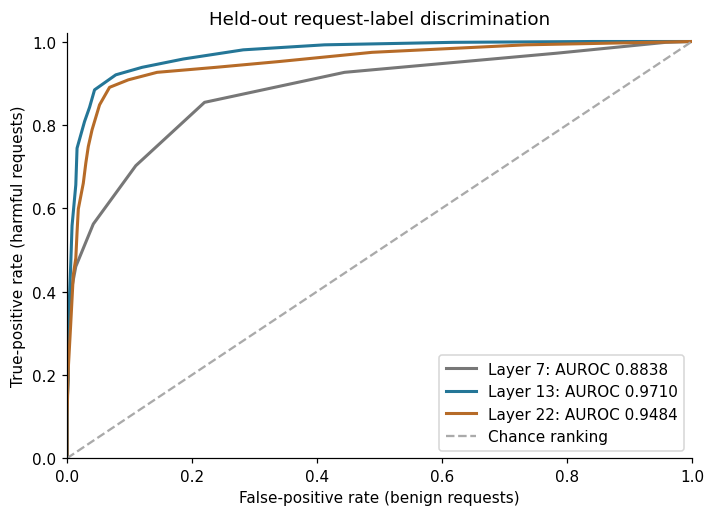

,layer,n_harmful,n_benign,auroc
0,7,500,500,0.883776
1,13,500,500,0.970966
2,22,500,500,0.948370


**Interpretation:** AUROC measures ranking of dataset labels, not refusal accuracy. Each layer uses its own frozen feature set. No classification threshold was fitted on these held-out requests. Topics were not held out in the archived run.

In [2]:
fig,ax=plt.subplots(figsize=(6.6,4.8));aucs=[]
for layer,color in zip(report_layers,['#777777','#247697','#b66b28']):
    d=frames[f'layer_{layer}_candidate_test_scores.csv']; y=(d.label=='harmful').to_numpy();s=d.candidate_firing_fraction.to_numpy()
    fpr,tpr=roc_points(y,s)
    auc=float(mannwhitneyu(s[y],s[~y]).statistic/(y.sum()*(~y).sum()))
    saved=next(v['heldout_auroc'] for v in summary['candidate_results'] if v['layer']==layer)
    assert np.isclose(auc,saved,atol=1e-10)
    assert np.isclose(np.sum(np.diff(fpr)*(tpr[1:]+tpr[:-1])/2),auc)
    ax.plot(fpr,tpr,label=f'Layer {layer}: AUROC {auc:.4f}',color=color,lw=2)
    aucs.append(dict(layer=layer,n_harmful=int(y.sum()),n_benign=int((~y).sum()),auroc=auc))
ax.plot([0,1],[0,1],'--',color='#aaaaaa',label='Chance ranking')
ax.set(xlabel='False-positive rate (benign requests)',ylabel='True-positive rate (harmful requests)',
       title='Held-out request-label discrimination',xlim=(0,1),ylim=(0,1.02));ax.legend()
show_save(fig,'01_heldout_roc');display(pd.DataFrame(aucs));pd.DataFrame(aucs).to_csv(REPORT_DIR/'recomputed_auroc.csv',index=False)
display(Markdown('**Interpretation:** AUROC measures ranking of dataset labels, not refusal accuracy. Each layer uses its own frozen feature set. No classification threshold was fitted on these held-out requests. Topics were not held out in the archived run.'))


## 2. Score overlap and benign activation

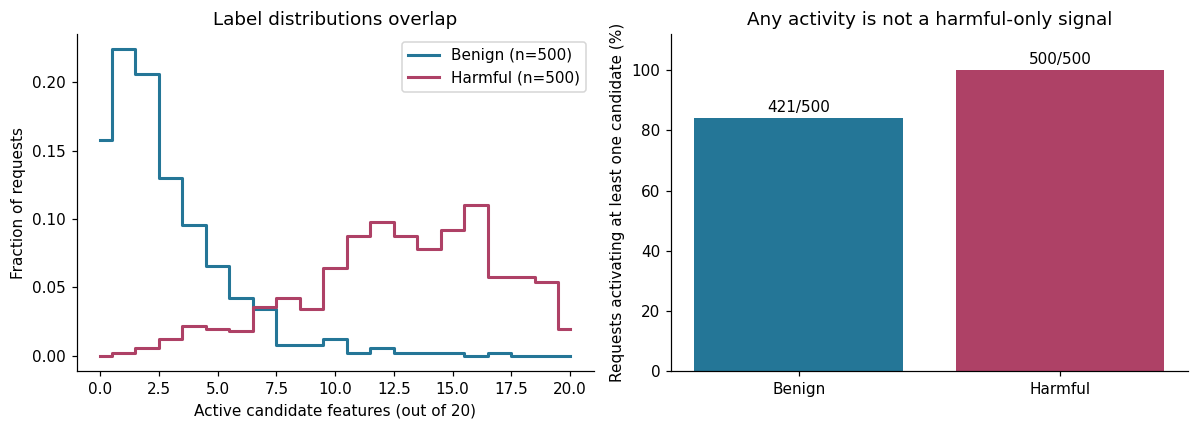

,n,nonzero,mean_active
label,,,
harmless,500,421,2.698
harmful,500,500,12.856


**421/500 benign requests** activate at least one candidate. Strong AUROC can coexist with this because the score uses the fraction of the group active, rather than merely checking whether any feature fires. This does not establish what each feature means.

In [3]:
d13=frames['layer_13_candidate_test_scores.csv'].copy()
c13=next(c for c in summary['candidate_results'] if c['layer']==13);k=len(c13['selected_ids'])
assert k>0
d13['active_count']=np.rint(d13.candidate_firing_fraction*k).astype(int)
assert np.allclose(d13.active_count/k,d13.candidate_firing_fraction)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for label,name in [('harmless','Benign'),('harmful','Harmful')]:
    g=d13[d13.label==label];counts=g.active_count.value_counts().reindex(range(k+1),fill_value=0)
    ax[0].step(range(k+1),counts/len(g),where='mid',lw=2,color=COLORS[label],label=f'{name} (n={len(g)})')
ax[0].set(xlabel=f'Active candidate features (out of {k})',ylabel='Fraction of requests',title='Label distributions overlap');ax[0].legend()
presence=d13.groupby('label').agg(n=('active_count','size'),nonzero=('active_count',lambda s:int((s>0).sum())),mean_active=('active_count','mean'))
presence=presence.reindex(['harmless','harmful'])
ax[1].bar(['Benign','Harmful'],100*presence.nonzero/presence.n,color=[COLORS['harmless'],COLORS['harmful']])
for i,(_,r) in enumerate(presence.iterrows()):ax[1].text(i,100*r.nonzero/r.n+2,f'{int(r.nonzero)}/{int(r.n)}',ha='center')
ax[1].set(ylabel='Requests activating at least one candidate (%)',ylim=(0,112),title='Any activity is not a harmful-only signal')
show_save(fig,'02_score_overlap_and_presence');display(presence);presence.to_csv(REPORT_DIR/'layer13_presence.csv')
b=presence.loc['harmless']
display(Markdown(f"**{int(b.nonzero)}/{int(b.n)} benign requests** activate at least one candidate. Strong AUROC can coexist with this because the score uses the fraction of the group active, rather than merely checking whether any feature fires. This does not establish what each feature means."))


## 3. Discovery-only feature selection

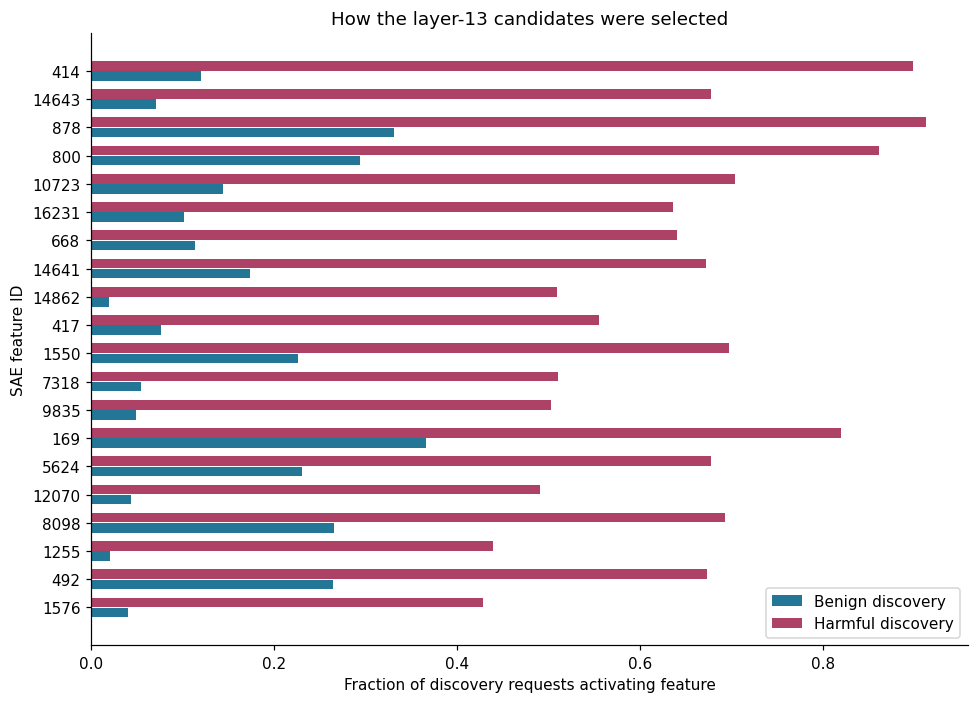

**Selection:** up to 20 positive firing-frequency differences were chosen from discovery data, with at least three harmful activations. This is a fixed selection budget, not evidence that the model has exactly 20 safety features. The archived ranking is unadjusted for topic; wording and topic can contribute to association.

In [4]:
r=frames['layer_13_candidate_ranking.csv'].sort_values(['frequency_difference','feature_id'],ascending=[True,False])
fig,ax=plt.subplots(figsize=(9,6.5));y=np.arange(len(r));den=config['discovery_per_group']
ax.barh(y-.18,r.harmless_count/den,height=.34,color=COLORS['harmless'],label='Benign discovery')
ax.barh(y+.18,r.harmful_count/den,height=.34,color=COLORS['harmful'],label='Harmful discovery')
ax.set(yticks=y,yticklabels=r.feature_id.astype(str),xlabel='Fraction of discovery requests activating feature',ylabel='SAE feature ID',title='How the layer-13 candidates were selected');ax.legend(loc='lower right')
show_save(fig,'03_candidate_discovery_frequencies')
display(Markdown(f"**Selection:** up to {config['candidate_top_k']} positive firing-frequency differences were chosen from discovery data, with at least three harmful activations. This is a fixed selection budget, not evidence that the model has exactly {config['candidate_top_k']} safety features. The archived ranking is unadjusted for topic; wording and topic can contribute to association."))


## 4. Inventory coverage is a separate question

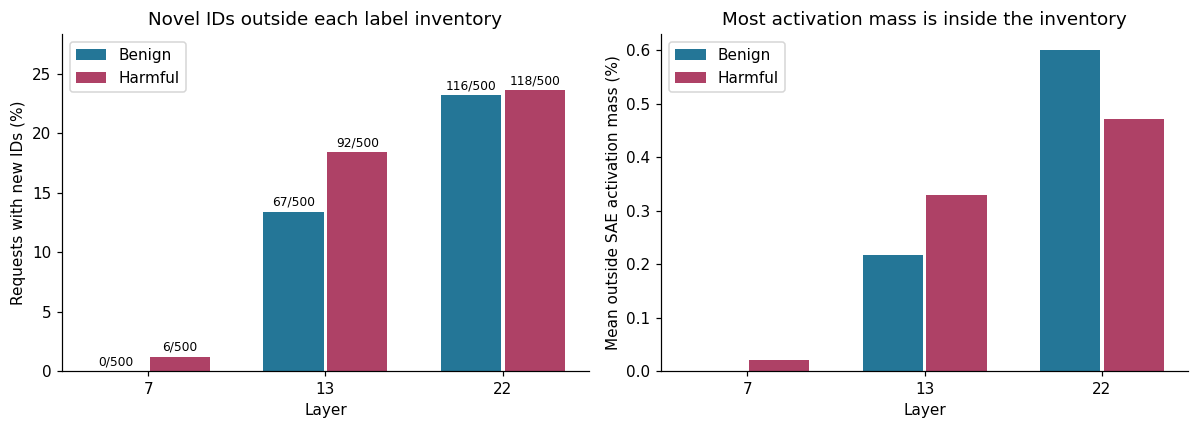

,layer,label,inventory_size,n,novel_requests,novel_rate,simultaneous_95pct_novel_rate_upper_bound,novel_rate_target_supported,mean_outside_mass
0,7,harmful,113,500,6,0.012,0.029459,False,0.000201
1,7,harmless,77,500,0,0.000,0.009529,True,0.000000
2,13,harmful,782,500,92,0.184,0.229084,False,0.003288
3,13,harmless,783,500,67,0.134,0.174552,False,0.002165
4,22,harmful,1465,500,118,0.236,0.284579,False,0.004717
5,22,harmless,1544,500,116,0.232,0.280347,False,0.006003


**These are the large discovery inventories, not the 20-feature candidate groups.** New IDs can carry little activation mass. A low mean outside mass does not establish saturation, completeness, or causal importance. The novelty target uses simultaneous one-sided bounds across six groups, not the observed rate alone. Dictionary scales also limit cross-layer interpretation.

In [5]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
x=np.arange(len(report_layers))
for label,offset,name in [('harmless',-.18,'Benign'),('harmful',.18,'Harmful')]:
    g=groups[groups.label==label].set_index('layer').loc[report_layers]
    bars=ax[0].bar(x+offset,g.novel_rate*100,width=.34,color=COLORS[label],label=name)
    for bar,(_,v) in zip(bars,g.iterrows()):ax[0].text(bar.get_x()+bar.get_width()/2,bar.get_height()+.5,f'{int(v.novel_requests)}/{int(v.n)}',ha='center',fontsize=8)
    ax[1].bar(x+offset,g.mean_outside_mass*100,width=.34,color=COLORS[label],label=name)
for a in ax:a.set(xticks=x,xticklabels=[str(l) for l in report_layers],xlabel='Layer');a.legend()
ax[0].set(ylabel='Requests with new IDs (%)',title='Novel IDs outside each label inventory');ax[0].margins(y=.2)
ax[1].set(ylabel='Mean outside SAE activation mass (%)',title='Most activation mass is inside the inventory')
show_save(fig,'04_inventory_coverage')
cols=['layer','label','inventory_size','n','novel_requests','novel_rate','simultaneous_95pct_novel_rate_upper_bound','novel_rate_target_supported','mean_outside_mass']
display(groups[cols].round(6));groups.to_csv(REPORT_DIR/'coverage_by_layer_label.csv',index=False)
display(Markdown('**These are the large discovery inventories, not the 20-feature candidate groups.** New IDs can carry little activation mass. A low mean outside mass does not establish saturation, completeness, or causal importance. The novelty target uses simultaneous one-sided bounds across six groups, not the observed rate alone. Dictionary scales also limit cross-layer interpretation.'))


## 5. Discovery growth across depth

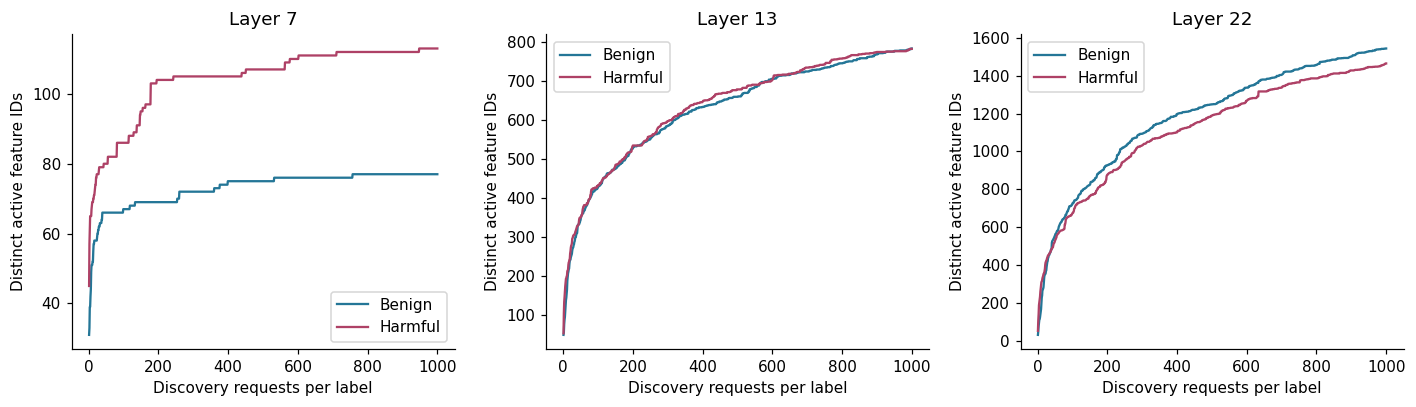

**The inventories freeze at the prespecified discovery budget.** A visually flattening curve is not proof of complete feature coverage. This study uses a different dataset and protocol from the earlier synthetic saturation experiment.

In [6]:
curves=frames['discovery_curves.csv'];fig,ax=plt.subplots(1,len(report_layers),figsize=(13,3.8),squeeze=False)
for a,layer in zip(ax[0],report_layers):
    for label,name in [('harmless','Benign'),('harmful','Harmful')]:
        g=curves[(curves.layer==layer)&(curves.label==label)]
        a.plot(g.n,g.union_size,label=name,color=COLORS[label])
    a.set(title=f'Layer {layer}',xlabel='Discovery requests per label',ylabel='Distinct active feature IDs');a.legend()
show_save(fig,'05_inventory_growth')
display(Markdown('**The inventories freeze at the prespecified discovery budget.** A visually flattening curve is not proof of complete feature coverage. This study uses a different dataset and protocol from the earlier synthetic saturation experiment.'))


## 6. Interpretation and next experiment

In [7]:
g13=groups[groups.layer==13];b=presence.loc['harmless'];a13=next(r['auroc'] for r in aucs if r['layer']==13)
unsupported=g13.loc[~g13.novel_rate_target_supported,'label'].tolist()
status='not supported for '+', '.join(unsupported) if unsupported else 'supported for both tested label groups under the specified bound'
display(Markdown(f"""## What we found

- The frozen layer-13 group contains **{k} candidates**, with held-out request-label **AUROC {a13:.6f}**.
- **{int(b.nonzero)}/{int(b.n)} benign requests** activate at least one candidate. Presence alone does not identify harmful intent.
- The layer-13 inventory novelty-rate target was **{status}**. High activation-mass coverage is a separate result.
- This experiment measures association. It generates no answers and establishes no causal refusal mechanism.

## What comes next?

We next examine measurement fidelity and causal influence: does SAE reconstruction preserve reviewed behavior, and does removing a selected group change refusal relative to controls? The map-audit experiment selected a **separate eight-feature group**; it must not be presented as an intervention on this entire 20-feature group.

Later persona experiments use the frozen candidate inventory to ask whether measured activity persists when the answer changes. Their behavioral evidence is separate from the request-label evidence here.

This result applies to the recorded model, SAE, token position, and split. It does not establish generalization to unseen topics, invariant alignment, or persona mimicry.
"""))


## What we found

- The frozen layer-13 group contains **20 candidates**, with held-out request-label **AUROC 0.970966**.
- **421/500 benign requests** activate at least one candidate. Presence alone does not identify harmful intent.
- The layer-13 inventory novelty-rate target was **not supported for harmful, harmless**. High activation-mass coverage is a separate result.
- This experiment measures association. It generates no answers and establishes no causal refusal mechanism.

## What comes next?

We next examine measurement fidelity and causal influence: does SAE reconstruction preserve reviewed behavior, and does removing a selected group change refusal relative to controls? The map-audit experiment selected a **separate eight-feature group**; it must not be presented as an intervention on this entire 20-feature group.

Later persona experiments use the frozen candidate inventory to ask whether measured activity persists when the answer changes. Their behavioral evidence is separate from the request-label evidence here.

This result applies to the recorded model, SAE, token position, and split. It does not establish generalization to unseen topics, invariant alignment, or persona mimicry.


This experiment identified a 20-feature candidate group at layer 13 whose activity distinguished harmful from benign request labels, achieving AUROC 0.971 on held-out
requests. However, 421 of 500 benign requests activated at least one candidate feature. This showed statistical association, but did not establish that the group controls
refusal.
